# Ensemble-Notebook: alle gespeicherten Modelle einsammeln, prüfen und blenden

**Idee:** In `Models/` liegen zu jedem fertigen Lauf `oof_*.npy` (Out-of-Fold-Vorhersagen auf Train) und `test_*.npy` (Testvorhersagen). Dieses Notebook
1. sammelt alle vollständigen Paare ein und prüft sie (Länge, AUC, defekte Läufe),
2. zeigt, wie ähnlich sich die Modelle sind (Korrelation),
3. vergleicht Blend-Methoden **ehrlich per verschachtelter Kreuzvalidierung** (Gewichte werden nur auf Teilen der Zeilen gelernt und auf dem Rest bewertet – so fällt Überanpassung der Gewichte auf),
4. schreibt die Submission(s) **als Wahrscheinlichkeiten** (0..1, keine 0/1-Werte).

**Verglichene Methoden:** gleiches Mittel (Wahrscheinlichkeiten / Logits / Ränge), bestes Einzelmodell, nicht-negative Gewichte per Logloss, Logistic-Regression-Stacking, Hill-Climbing mit Zurücklegen.

**Deine Projektdateien bleiben unangetastet:** nur lesen aus `Models/`, schreiben nach `Results/submissions/` (neue Dateien).

In [1]:
import os, sys, re, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.stats import rankdata
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

warnings.filterwarnings("ignore")

_p = Path.cwd().resolve()
for _cand in [_p, *_p.parents]:
    if (_cand / "src").is_dir():
        ROOT = _cand
        break
else:
    raise FileNotFoundError("Ordner 'src' nicht gefunden – Notebook im Projektordner starten.")
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
from src import config as cfg
print("Projektordner:", ROOT, "| Models:", cfg.MODELS_DIR)

Projektordner: /home/cgd16/Desktop/Projekte/04 - Kaggle/Playground_Series_Season_6_Episode_10_Predicting_Airline_Satisfaction | Models: /home/cgd16/Desktop/Projekte/04 - Kaggle/Playground_Series_Season_6_Episode_10_Predicting_Airline_Satisfaction/Models


## Einstellungen

In [2]:
MAX_DROP = 0.003          # Modelle, deren OOF-AUC mehr als so viel unter dem besten liegt, werden ausgeschlossen
EXCLUDE = []              # zusaetzlich von Hand ausschliessen (exakte Namen aus der Tabelle unten)
OUTER_SPLITS = 5          # Folds der verschachtelten Validierung
OUTER_SEED = 777
HC_ITERS = 30             # max. Schritte beim Hill-Climbing
HC_SUB = 200_000          # Zeilen-Subsample fuers Hill-Climbing (Tempo)
MIN_GAIN = 2e-5           # Gewinn gegenueber 'equal_logit', ab dem eine komplexere Methode genommen wird
WRITE = True              # Submission(s) schreiben

# Defekte Seeds ausschliessen: Aus den Fold-Checkpoints ein "virtuelles" Modell nur mit guten Seeds bauen.
EXTRA = [
    dict(name="lgbm_fs07_noOrigRows_goodseeds", folder="lgbm_fs07_noOrigRows", model="lgbm",
         seeds=[2, 8, 10, 42, 46, 2026], K=10),
]

## 1) Daten & Vorhersagen einsammeln

In [3]:
y = (pd.read_csv(cfg.DATA_DIR / cfg.TRAIN_FILE, usecols=[cfg.TARGET])[cfg.TARGET]
       .astype(str).str.strip().str.lower().eq("satisfied")).astype(int).values \
    if not pd.api.types.is_numeric_dtype(pd.read_csv(cfg.DATA_DIR / cfg.TRAIN_FILE, usecols=[cfg.TARGET])[cfg.TARGET]) \
    else pd.read_csv(cfg.DATA_DIR / cfg.TRAIN_FILE, usecols=[cfg.TARGET])[cfg.TARGET].astype(int).values
test_ids = pd.read_csv(cfg.DATA_DIR / cfg.TEST_FILE, usecols=[cfg.ID_COL])[cfg.ID_COL].values
sample_sub = pd.read_csv(cfg.DATA_DIR / cfg.SAMPLE_SUB_FILE)
N_TRAIN, N_TEST = len(y), len(test_ids)
print(f"Train {N_TRAIN} | Test {N_TEST} | Basisrate {y.mean():.4f}")

POOL = {}      # Name -> dict(oof, test)
INFO = []      # Zeilen fuer die Uebersicht

def add_model(name, oof, te, source):
    oof, te = np.asarray(oof, dtype=np.float32), np.asarray(te, dtype=np.float32)
    ok = (len(oof) == N_TRAIN) and (len(te) == N_TEST) and np.isfinite(oof).all() and np.isfinite(te).all()
    if not ok:
        INFO.append(dict(name=name, source=source, status="uebersprungen (Laenge/NaN)", auc=np.nan)); return
    POOL[name] = dict(oof=oof, test=te)
    INFO.append(dict(name=name, source=source, status="ok", auc=roc_auc_score(y, oof)))

# a) fertige oof_/test_-Paare
for f in sorted(cfg.MODELS_DIR.glob("oof_*.npy")):
    name = f.stem[len("oof_"):]
    tf = cfg.MODELS_DIR / f"test_{name}.npy"
    if not tf.exists():
        INFO.append(dict(name=name, source="Datei", status="test-Datei fehlt", auc=np.nan)); continue
    add_model(name, np.load(f), np.load(tf), "Datei")

# b) virtuelle Modelle aus Fold-Checkpoints (z. B. nur gute Seeds)
for ex in EXTRA:
    d = cfg.MODELS_DIR / "saved_models" / ex["folder"]
    if not d.exists():
        print(f"[EXTRA] Ordner fehlt, uebersprungen: {d.name}"); continue
    oof = np.zeros(N_TRAIN); te = np.zeros(N_TEST); missing = 0
    for seed in ex["seeds"]:
        for fold, (tr, va) in enumerate(StratifiedKFold(ex["K"], shuffle=True, random_state=seed).split(y, y), 1):
            fv, ft = d / f"pred_va_{ex['model']}_seed{seed}_fold{fold}.npy", d / f"pred_te_{ex['model']}_seed{seed}_fold{fold}.npy"
            if not (fv.exists() and ft.exists()):
                missing += 1; continue
            oof[va] += np.load(fv) / len(ex["seeds"])
            te += np.load(ft) / (ex["K"] * len(ex["seeds"]))
    if missing:
        print(f"[EXTRA] {ex['name']}: {missing} Fold-Dateien fehlen, uebersprungen"); continue
    add_model(ex["name"], oof, te, "Checkpoints")

info = pd.DataFrame(INFO).set_index("name").sort_values("auc", ascending=False)
display(info.round(6))

Train 699635 | Test 299844 | Basisrate 0.4436


,source,status,auc
name,,,
xgb_fs07_noOrigRows_s42-2026-10-23-16-2-8-46,Datei,ok,0.961248
lgbm_fs07_noOrigRows_goodseeds,Checkpoints,ok,0.961239
xgb_fs05_s42-2026-10-23-16-2-8-46,Datei,ok,0.961155
cat_fs07_noOrigRows_s42-2026-10-23-16-2-8-46,Datei,ok,0.961110
cat_fs05_s42-2026-10-23-16-2-8-46,Datei,ok,0.960953
lgbm_fs07_noOrigRows_dbg_s42,Datei,ok,0.960881
xgb_fs06_s42-2026-10-23-16-2-8-46,Datei,ok,0.960823
cat_fs06_s42-2026-10-23-16-2-8-46,Datei,ok,0.960597
lgbm_fs06_s42-2026-10-23-16-2-8-46,Datei,ok,0.959469


In [4]:
# Auswahl: defekte / deutlich schwaechere Laeufe raus
best = info["auc"].max()
too_weak = [n for n in POOL if best - info.loc[n, "auc"] > MAX_DROP]
sel = [n for n in POOL if n not in too_weak and n not in EXCLUDE]
if too_weak: print(f"Ausgeschlossen (> {MAX_DROP} unter dem besten): {too_weak}")
if EXCLUDE:  print(f"Von Hand ausgeschlossen: {EXCLUDE}")
sel = sorted(sel, key=lambda n: -info.loc[n, "auc"])
print(f"\n{len(sel)} Modelle im Blend-Pool:")
for n in sel: print(f"  {info.loc[n, 'auc']:.6f}  {n}")

P = np.column_stack([POOL[n]["oof"] for n in sel]).astype(np.float64)      # Train (OOF)
PT = np.column_stack([POOL[n]["test"] for n in sel]).astype(np.float64)    # Test
M = P.shape[1]
assert M >= 2, "Mindestens 2 Modelle noetig"

Ausgeschlossen (> 0.003 unter dem besten): ['lgbm_fs07_noOrigRows_s42-2026-10-23-16-2-8-46']

10 Modelle im Blend-Pool:
  0.961248  xgb_fs07_noOrigRows_s42-2026-10-23-16-2-8-46
  0.961239  lgbm_fs07_noOrigRows_goodseeds
  0.961155  xgb_fs05_s42-2026-10-23-16-2-8-46
  0.961110  cat_fs07_noOrigRows_s42-2026-10-23-16-2-8-46
  0.960953  cat_fs05_s42-2026-10-23-16-2-8-46
  0.960881  lgbm_fs07_noOrigRows_dbg_s42
  0.960823  xgb_fs06_s42-2026-10-23-16-2-8-46
  0.960597  cat_fs06_s42-2026-10-23-16-2-8-46
  0.959469  lgbm_fs06_s42-2026-10-23-16-2-8-46
  0.959438  lgbm_fs05_s42-2026-10-23-16-2-8-46


## 2) Wie ähnlich sind die Modelle?
Hohe Korrelation = wenig Gewinn durch Blenden. Gewinn entsteht vor allem durch *unterschiedliche* Fehler.

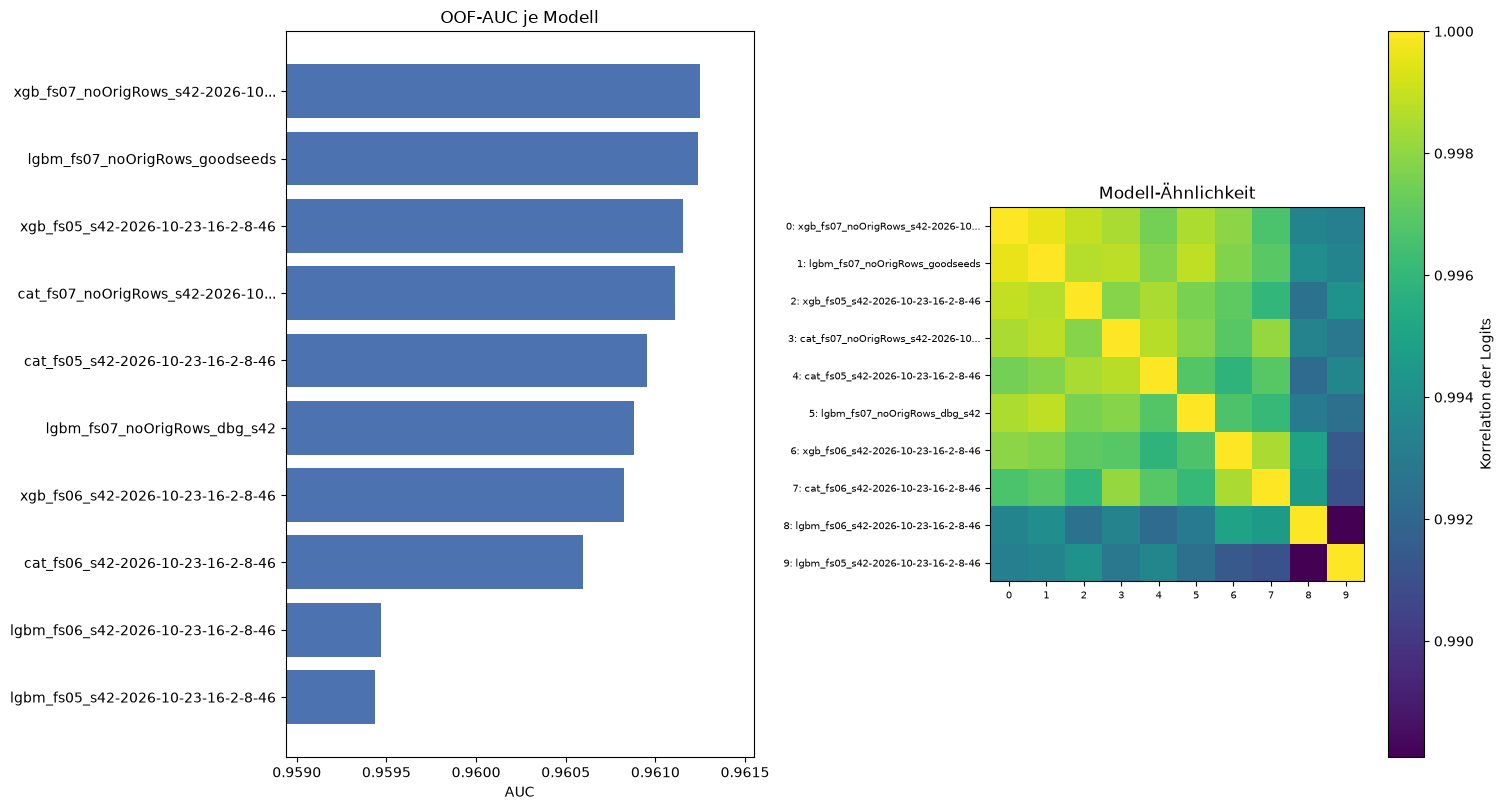

Korrelation der Logits: min 0.9881 | Mittel 0.9959 | max 0.9996


In [5]:
def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

rng = np.random.default_rng(0)
sub = rng.choice(N_TRAIN, size=min(150_000, N_TRAIN), replace=False)
Z_sub = logit(P[sub])
C = np.corrcoef(Z_sub.T)
short = [n if len(n) <= 34 else n[:31] + "..." for n in sel]

fig, axes = plt.subplots(1, 2, figsize=(15, 0.42 * M + 4))
a = info.loc[sel, "auc"].values[::-1]
axes[0].barh(short[::-1], a, color="#4c72b0")
axes[0].set_xlim(a.min() - 0.0005, a.max() + 0.0003)
axes[0].set_title("OOF-AUC je Modell"); axes[0].set_xlabel("AUC")
im = axes[1].imshow(C, vmin=C.min(), vmax=1, cmap="viridis")
axes[1].set_xticks(range(M)); axes[1].set_xticklabels(range(M), fontsize=7)
axes[1].set_yticks(range(M)); axes[1].set_yticklabels([f"{i}: {s}" for i, s in enumerate(short)], fontsize=7)
plt.colorbar(im, ax=axes[1], label="Korrelation der Logits")
axes[1].set_title("Modell-Ähnlichkeit")
plt.tight_layout(); plt.show()

off = C[np.triu_indices(M, 1)]
print(f"Korrelation der Logits: min {off.min():.4f} | Mittel {off.mean():.4f} | max {off.max():.4f}")

## 3) Blend-Methoden (verschachtelte Validierung)
Jede Methode lernt ihre Gewichte nur auf 4 von 5 Teilen der Zeilen und wird auf dem 5. Teil bewertet. Die Ausgabe ist die mittlere AUC der 5 Teile. Dadurch sehen komplexe Methoden nicht besser aus, nur weil sie die OOF-Daten auswendig lernen.

| Methode | Beschreibung |
|---|---|
| `equal_prob` | Mittel der Wahrscheinlichkeiten |
| `equal_logit` | Mittel der Logits |
| `equal_rank` | Mittel der Ränge (nur Vergleich, **keine** Wahrscheinlichkeiten) |
| `best_single` | nur das beste Einzelmodell |
| `nnls_logloss` | nicht-negative Gewichte + Achsenabschnitt, per Logloss gelernt |
| `lr_stack` | Logistic Regression auf den Logits |
| `hill_climb` | gierig Modelle (mit Zurücklegen) hinzufügen, solange die AUC steigt |

In [7]:
class LinearModel:
    """score = Z @ w + b   (Z = Logits oder Wahrscheinlichkeiten) -> proba ist eine echte Wahrscheinlichkeit."""
    def __init__(self, w, b=0.0, space="logit"):
        self.w, self.b, self.space = np.asarray(w, float), float(b), space
    def _Z(self, P): return logit(P) if self.space == "logit" else P
    def score(self, P): return self._Z(P) @ self.w + self.b
    def proba(self, P):
        s = self.score(P)
        return sigmoid(s) if self.space == "logit" else np.clip(s, 0, 1)

class RankModel:
    def __init__(self, w): self.w = np.asarray(w, float)
    def score(self, P): return np.column_stack([rankdata(P[:, j]) / len(P) for j in range(P.shape[1])]) @ self.w
    proba = None   # Raenge sind keine Wahrscheinlichkeiten

def fit_equal(space):
    return lambda P, y_: (RankModel(np.ones(P.shape[1]) / P.shape[1]) if space == "rank"
                          else LinearModel(np.ones(P.shape[1]) / P.shape[1], 0.0, space))

def fit_best_single(P, y_):
    idx = np.random.default_rng(1).choice(len(y_), size=min(len(y_), 200_000), replace=False)
    a = [roc_auc_score(y_[idx], P[idx, j]) for j in range(P.shape[1])]
    w = np.zeros(P.shape[1]); w[int(np.argmax(a))] = 1.0
    return LinearModel(w, 0.0, "logit")

def fit_nnls(P, y_):
    Z = logit(P); m = Z.shape[1]
    def f(th):
        w, b = th[:m], th[m]
        z = Z @ w + b
        g = sigmoid(z) - y_
        return np.mean(np.logaddexp(0, z) - y_ * z), np.r_[Z.T @ g / len(y_), g.mean()]
    res = minimize(f, np.r_[np.ones(m) / m, 0.0], jac=True, method="L-BFGS-B",
                   bounds=[(0, None)] * m + [(None, None)])
    return LinearModel(res.x[:m], res.x[m], "logit")

def fit_lr(P, y_):
    lr = LogisticRegression(C=1.0, max_iter=300).fit(logit(P), y_)
    return LinearModel(lr.coef_[0], lr.intercept_[0], "logit")

def fit_hill(P, y_, iters=HC_ITERS, sub_n=HC_SUB):
    Z = logit(P); m = Z.shape[1]
    idx = np.random.default_rng(2).choice(len(y_), size=min(len(y_), sub_n), replace=False)
    Zs, ys = Z[idx], y_[idx]
    counts, cur, k = np.zeros(m), np.zeros(len(ys)), 0
    best_auc, best_counts, stall = -1.0, counts.copy(), 0
    for _ in range(iters):
        sc = [roc_auc_score(ys, (cur + Zs[:, j]) / (k + 1)) for j in range(m)]
        j = int(np.argmax(sc))
        counts[j] += 1; cur += Zs[:, j]; k += 1
        if sc[j] > best_auc + 1e-7:
            best_auc, best_counts, stall = sc[j], counts.copy(), 0
        else:
            stall += 1
            if stall >= 4: break
    return LinearModel(best_counts / best_counts.sum(), 0.0, "logit")

METHODS = {
    "equal_prob":   fit_equal("prob"),
    "equal_logit":  fit_equal("logit"),
    "equal_rank":   fit_equal("rank"),
    "best_single":  fit_best_single,
    "nnls_logloss": fit_nnls,
    "lr_stack":     fit_lr,
    "hill_climb":   fit_hill,
}

t0 = time.time()
folds = list(StratifiedKFold(OUTER_SPLITS, shuffle=True, random_state=OUTER_SEED).split(P, y))
fold_auc = {k: [] for k in METHODS}
for i, (tr, va) in enumerate(folds, 1):
    for name, fit in METHODS.items():
        mdl = fit(P[tr], y[tr])
        fold_auc[name].append(roc_auc_score(y[va], mdl.score(P[va])))
    print(f"Fold {i}/{OUTER_SPLITS} fertig ({time.time() - t0:.0f}s)")

base = np.array(fold_auc["equal_logit"])
rows = []
for name, a in fold_auc.items():
    a = np.array(a)
    rows.append(dict(methode=name, auc_mean=a.mean(), auc_std=a.std(ddof=1),
                     delta_vs_equal_logit=(a - base).mean(), folds_besser=int((a > base).sum()),
                     wahrscheinlichkeit="ja" if name != "equal_rank" else "nein (Raenge)"))
res = pd.DataFrame(rows).set_index("methode").sort_values("auc_mean", ascending=False)
display(res.round(6))
print(f"Bestes Einzelmodell (OOF, ohne Validierung): {info.loc[sel[0], 'auc']:.6f}")

Fold 1/5 fertig (9s)
Fold 2/5 fertig (16s)
Fold 3/5 fertig (23s)
Fold 4/5 fertig (34s)
Fold 5/5 fertig (41s)


,auc_mean,auc_std,delta_vs_equal_logit,folds_besser,wahrscheinlichkeit
methode,,,,,
lr_stack,0.961326,0.000750,0.000084,5,ja
hill_climb,0.961318,0.000737,0.000076,5,ja
nnls_logloss,0.961317,0.000753,0.000075,5,ja
equal_rank,0.961243,0.000741,0.000002,3,nein (Raenge)
equal_logit,0.961242,0.000740,0.000000,0,ja
best_single,0.961240,0.000757,-0.000001,3,ja
equal_prob,0.961232,0.000755,-0.000009,1,ja


Bestes Einzelmodell (OOF, ohne Validierung): 0.961248


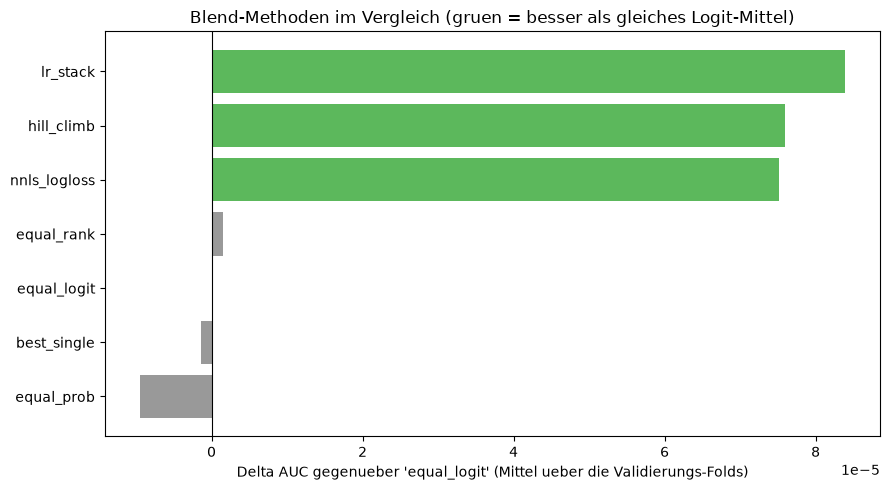

In [8]:
r = res.sort_values("delta_vs_equal_logit")
col = ["#5cb85c" if v > MIN_GAIN else ("#d9534f" if v < -MIN_GAIN else "#999999") for v in r["delta_vs_equal_logit"]]
fig, ax = plt.subplots(figsize=(9, 0.5 * len(r) + 1.5))
ax.barh(r.index, r["delta_vs_equal_logit"], color=col)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Delta AUC gegenueber 'equal_logit' (Mittel ueber die Validierungs-Folds)")
ax.set_title("Blend-Methoden im Vergleich (gruen = besser als gleiches Logit-Mittel)")
plt.tight_layout(); plt.show()

## 4) Finale Methode wählen & Gewichte ansehen
Regel: Es wird die Methode mit der höchsten validierten AUC gewählt – **aber nur, wenn sie `equal_logit` um mindestens `MIN_GAIN` schlägt**. Sonst gewinnt das einfache gleiche Logit-Mittel (robuster). `equal_rank` wird nie geschrieben, weil Ränge keine Wahrscheinlichkeiten sind.

Beste validierte Methode: lr_stack (Gewinn gegenueber equal_logit: +0.000084) -> FINAL = lr_stack

Gewichte / Koeffizienten (Logit-Raum):
xgb_fs05_s42-2026-10-23-16-2-8-46               0.2890
xgb_fs07_noOrigRows_s42-2026-10-23-16-2-8-46    0.2747
lgbm_fs07_noOrigRows_goodseeds                  0.2015
cat_fs07_noOrigRows_s42-2026-10-23-16-2-8-46    0.1636
xgb_fs06_s42-2026-10-23-16-2-8-46               0.1433
cat_fs05_s42-2026-10-23-16-2-8-46               0.0625
lgbm_fs05_s42-2026-10-23-16-2-8-46             -0.0144
cat_fs06_s42-2026-10-23-16-2-8-46              -0.0153
lgbm_fs06_s42-2026-10-23-16-2-8-46             -0.0208
lgbm_fs07_noOrigRows_dbg_s42                   -0.0900
Achsenabschnitt: -0.0069
Summe der Gewichte: 0.9939 | Gewicht auf <= 0: 4 von 10 Modellen


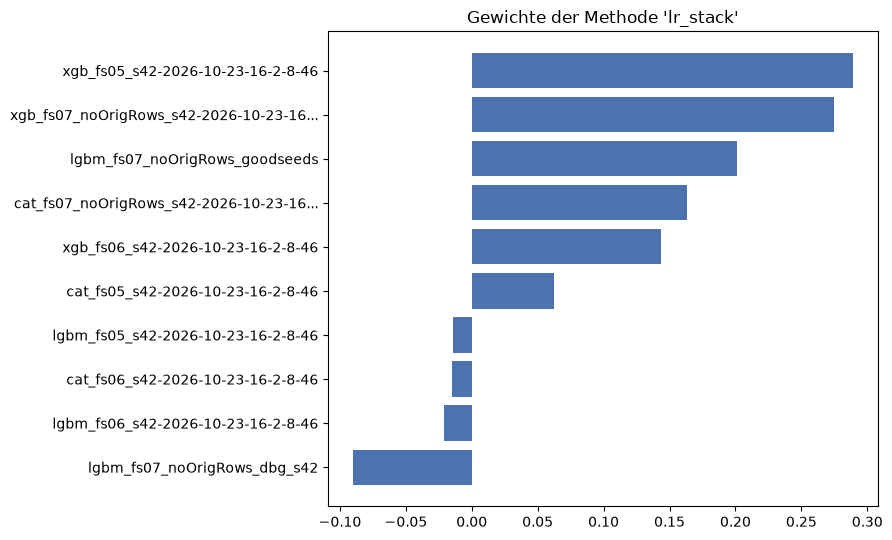

In [9]:
cands = res[res.index != "equal_rank"]
top = cands["auc_mean"].idxmax()
gain = cands.loc[top, "auc_mean"] - cands.loc["equal_logit", "auc_mean"]
FINAL = top if gain >= MIN_GAIN else "equal_logit"
print(f"Beste validierte Methode: {top} (Gewinn gegenueber equal_logit: {gain:+.6f}) -> FINAL = {FINAL}")

final_model = METHODS[FINAL](P, y)
w = pd.Series(final_model.w, index=sel)
print("\nGewichte / Koeffizienten (Logit-Raum):" if final_model.space == "logit" else "\nGewichte:")
print(w.round(4).sort_values(ascending=False).to_string())
if abs(final_model.b) > 0: print(f"Achsenabschnitt: {final_model.b:+.4f}")
print(f"Summe der Gewichte: {w.sum():.4f} | Gewicht auf <= 0: {(w <= 1e-9).sum()} von {len(w)} Modellen")

fig, ax = plt.subplots(figsize=(9, 0.4 * len(w) + 1.5))
ww = w.sort_values()
ax.barh([n if len(n) <= 40 else n[:37] + "..." for n in ww.index], ww.values, color="#4c72b0")
ax.set_title(f"Gewichte der Methode '{FINAL}'"); plt.tight_layout(); plt.show()

## 5) Submission schreiben (Wahrscheinlichkeiten)

In [10]:
from datetime import datetime

def write_sub(method_name, model, nested_auc):
    p = np.clip(model.proba(PT), 0.0, 1.0)
    id_col, target_col = sample_sub.columns[0], sample_sub.columns[1]
    sub = sample_sub.copy()
    sub[target_col] = pd.Series(p, index=test_ids).reindex(sub[id_col].values).values
    assert sub[target_col].notna().all() and len(sub) == N_TEST
    assert sub[target_col].between(0, 1).all()
    assert sub[target_col].nunique() > 10, "Submission wirkt binaer/diskret!"
    cfg.SUBMISSIONS_DIR.mkdir(parents=True, exist_ok=True)
    path = cfg.SUBMISSIONS_DIR / f"sub_{datetime.now():%Y%m%d_%H%M}_ensemble_{method_name}_cv{nested_auc:.4f}.csv"
    sub.to_csv(path, index=False)
    print(f"gespeichert: {path.name} | Mittel {p.mean():.4f} | Std {p.std():.4f} | eindeutige Werte {sub[target_col].nunique()}")
    return path

oof_p = final_model.proba(P)
print(f"Train-OOF-Blend: Mittel {oof_p.mean():.4f}, Std {oof_p.std():.4f} (zum Vergleich mit den Testwerten unten)")

if WRITE:
    write_sub(FINAL, final_model, res.loc[FINAL, "auc_mean"])
    if FINAL != "equal_logit":      # zusaetzlich die einfache Variante als Alternative
        write_sub("equal_logit", METHODS["equal_logit"](P, y), res.loc["equal_logit", "auc_mean"])
else:
    print("WRITE = False -> keine Datei geschrieben")

Train-OOF-Blend: Mittel 0.4436, Std 0.4328 (zum Vergleich mit den Testwerten unten)
gespeichert: sub_20261012_0559_ensemble_lr_stack_cv0.9613.csv | Mittel 0.4438 | Std 0.4328 | eindeutige Werte 299844
gespeichert: sub_20261012_0559_ensemble_equal_logit_cv0.9612.csv | Mittel 0.4446 | Std 0.4328 | eindeutige Werte 299844


## Lesehilfe
- **Korrelation der Logits** nahe 1 (z. B. > 0.99): Die Modelle machen fast dieselben Fehler → Blenden bringt wenig. Gewinn kommt von Modellen, die sich deutlich unterscheiden (andere Familien, andere Features, MLP).
- **Delta ≤ 0.00002:** Der Unterschied zwischen Methoden ist praktisch Rauschen → einfaches `equal_logit` nehmen.
- **`nnls_logloss`/`lr_stack` mit vielen Gewichten ≈ 0** bedeutet: nur wenige Modelle tragen, der Rest ist überflüssig.
- **Test-Mittel/Std** sollten ähnlich zu den Train-OOF-Werten sein (kleine Abweichungen sind normal, weil Testvorhersagen Mittel vieler Fold-Modelle sind und glatter ausfallen).
- **Public LB:** Vergleiche das Ergebnis mit deinem besten (0.96092). Wähle als finale 2 Submissions möglichst *unterschiedliche* Ansätze (z. B. diese plus die einfache Variante), nicht zwei fast identische.
- **Grenzen:** Die OOF-Vorhersagen stammen aus verschiedenen Läufen mit unterschiedlichen Fold-Aufteilungen. Das ist beim Blenden üblich und bringt eine kleine Restoptimistik mit sich, die die verschachtelte Validierung nicht komplett entfernt.